In [1]:
#XLNET MODEL

In [2]:
import tensorflow as tf
from transformers import XLNetTokenizer, TFXLNetForSequenceClassification
from sklearn.preprocessing import LabelEncoder
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [3]:
import re
def load_data(file_path):
    return pd.read_csv(file_path, delimiter=';', header=None, names=['text', 'label'])

# Load datasets
train_data = load_data('/content/train.txt')
val_data = load_data('/content/val.txt')
test_data = load_data('/content/test.txt')



In [4]:
# Clean text and encode labels
def clean_text(text):
    text = text.lower()  # Convert to lowercase
    text = re.sub(r'[^\w\s]', '', text)  # Remove punctuation
    return text

train_data['text'] = train_data['text'].apply(clean_text)
val_data['text'] = val_data['text'].apply(clean_text)
test_data['text'] = test_data['text'].apply(clean_text)


In [5]:
label_encoder = LabelEncoder()
train_data['label'] = label_encoder.fit_transform(train_data['label'])
val_data['label'] = label_encoder.transform(val_data['label'])
test_data['label'] = label_encoder.transform(test_data['label'])


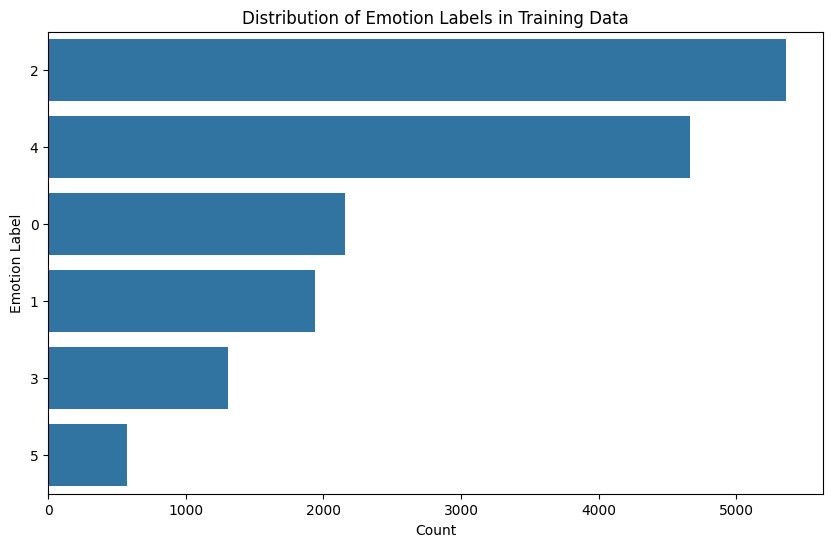

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plotting the distribution of labels
plt.figure(figsize=(10, 6))
sns.countplot(y='label', data=train_data, order=train_data['label'].value_counts().index)
plt.title('Distribution of Emotion Labels in Training Data')
plt.xlabel('Count')
plt.ylabel('Emotion Label')
plt.show()


In [7]:
# Print the classes and their corresponding integers
label_mapping = dict(zip(label_encoder.classes_, range(len(label_encoder.classes_))))
print("Label mapping:", label_mapping)


Label mapping: {'anger': 0, 'fear': 1, 'joy': 2, 'love': 3, 'sadness': 4, 'surprise': 5}


In [8]:
# Import the XLNetTokenizer
from transformers import XLNetTokenizer

# Initialize the XLNet tokenizer
tokenizer = XLNetTokenizer.from_pretrained('xlnet-base-cased')

def tokenize_and_encode(sentences, max_len=128):
    return tokenizer(sentences, padding=True, truncation=True, max_length=max_len, return_tensors="tf")

# Tokenize and encode the datasets
train_encodings = tokenize_and_encode(train_data['text'].tolist())
val_encodings = tokenize_and_encode(val_data['text'].tolist())
test_encodings = tokenize_and_encode(test_data['text'].tolist())


/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


spiece.model:   0%|          | 0.00/798k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.38M [00:00<?, ?B/s]

/usr/local/lib/python3.10/dist-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


config.json:   0%|          | 0.00/760 [00:00<?, ?B/s]

In [9]:
# Import the XLNet sequence classification model
from transformers import TFXLNetForSequenceClassification

# Initialize the XLNet model for sequence classification
model = TFXLNetForSequenceClassification.from_pretrained('xlnet-base-cased', num_labels=len(label_encoder.classes_))



tf_model.h5:   0%|          | 0.00/565M [00:00<?, ?B/s]

/usr/local/lib/python3.10/dist-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer TruncatedNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(
Some layers from the model checkpoint at xlnet-base-cased were not used when initializing TFXLNetForSequenceClassification: ['lm_loss']
- This IS expected if you are initializing TFXLNetForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFXLNetForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a Be

In [10]:
# Compile the model
optimizer = tf.keras.optimizers.Adam(learning_rate=5e-5)
loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
model.compile(optimizer=optimizer, loss=loss, metrics=['accuracy'])



In [11]:
# Prepare the datasets for training
train_dataset = tf.data.Dataset.from_tensor_slices(({
    'input_ids': train_encodings['input_ids'],
    'attention_mask': train_encodings['attention_mask']
}, train_data['label'])).batch(32)

val_dataset = tf.data.Dataset.from_tensor_slices(({
    'input_ids': val_encodings['input_ids'],
    'attention_mask': val_encodings['attention_mask']
}, val_data['label'])).batch(32)



In [12]:
# Train the model
history = model.fit(train_dataset, epochs=20, validation_data=val_dataset)


Epoch 1/20


Cause: for/else statement not yet supported
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: for/else statement not yet supported
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


500/500 [==============================] - 532s 849ms/step - loss: 0.6243 - accuracy: 0.7774 - val_loss: 0.1835 - val_accuracy: 0.9290
Epoch 2/20
500/500 [==============================] - 411s 822ms/step - loss: 0.1737 - accuracy: 0.9305 - val_loss: 0.1591 - val_accuracy: 0.9400
Epoch 3/20
500/500 [==============================] - 411s 821ms/step - loss: 0.1267 - accuracy: 0.9419 - val_loss: 0.1668 - val_accuracy: 0.9265
Epoch 4/20
500/500 [==============================] - 411s 822ms/step - loss: 0.1091 - accuracy: 0.9488 - val_loss: 0.1585 - val_accuracy: 0.9405
Epoch 5/20
500/500 [==============================] - 402s 803ms/step - loss: 0.1019 - accuracy: 0.9511 - val_loss: 0.1582 - val_accuracy: 0.9345
Epoch 6/20
500/500 [==============================] - 401s 803ms/step - loss: 0.0977 - accuracy: 0.9549 - val_loss: 0.1704 - val_accuracy: 0.9365
Epoch 7/20
500/500 [==============================] - 402s 803ms/step - loss: 0.0884 - accuracy: 0.9608 - val_loss: 0.1589 - val_accura

In [13]:
import os

# Path to save the model
save_directory = '/content/drive/MyDrive/NLP_Model/XLNET_MODEL'
os.makedirs(save_directory, exist_ok=True)

# Save the model and tokenizer
model.save_pretrained(save_directory)
tokenizer.save_pretrained(save_directory)


('/content/drive/MyDrive/NLP_Model/XLNET_MODEL/tokenizer_config.json',
 '/content/drive/MyDrive/NLP_Model/XLNET_MODEL/special_tokens_map.json',
 '/content/drive/MyDrive/NLP_Model/XLNET_MODEL/spiece.model',
 '/content/drive/MyDrive/NLP_Model/XLNET_MODEL/added_tokens.json')

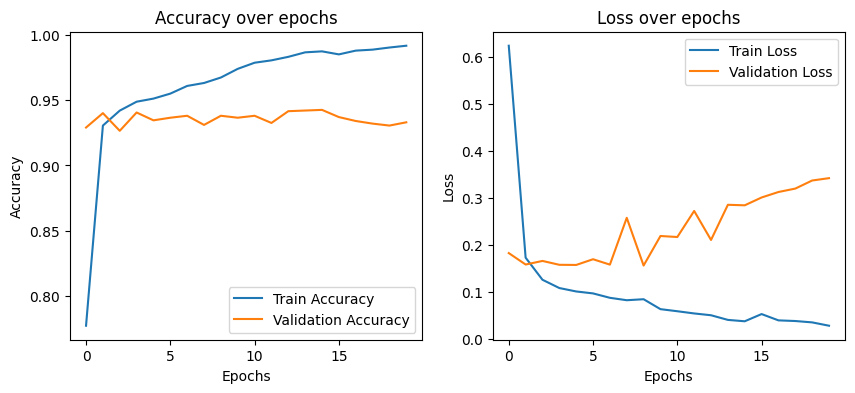

In [14]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


In [15]:
# Cell 14: View the model summary
model.summary()


Model: "tfxl_net_for_sequence_classification"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 transformer (TFXLNetMainLa  multiple                  116718336 
 yer)                                                            
                                                                 
 sequence_summary (TFSequen  multiple                  590592    
 ceSummary)                                                      
                                                                 
 logits_proj (Dense)         multiple                  4614      
                                                                 
Total params: 117313542 (447.52 MB)
Trainable params: 117313542 (447.52 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [16]:
from sklearn.metrics import classification_report, accuracy_score, precision_recall_fscore_support

# Assuming 'test_encodings' and 'test_data' are already prepared and available
test_dataset = tf.data.Dataset.from_tensor_slices(({
    'input_ids': test_encodings['input_ids'],
    'attention_mask': test_encodings['attention_mask']
}, test_data['label'])).batch(32)

# Get predictions for the test set
y_pred = model.predict(test_dataset)
y_pred_labels = np.argmax(y_pred.logits, axis=1)

# True labels
y_true = test_data['label'].values

# Calculate and print accuracy
accuracy = accuracy_score(y_true, y_pred_labels)
print(f"Accuracy: {accuracy}")

# Detailed classification report
report = classification_report(y_true, y_pred_labels, target_names=label_encoder.classes_)
print(report)

# If you need precision, recall, fscore separately
precision, recall, fscore, _ = precision_recall_fscore_support(y_true, y_pred_labels, average='weighted')
print(f"Precision: {precision}\nRecall: {recall}\nF-Score: {fscore}")


63/63 [==============================] - 18s 181ms/step
Accuracy: 0.932
              precision    recall  f1-score   support

       anger       0.98      0.92      0.95       275
        fear       0.86      0.96      0.91       224
         joy       0.93      0.97      0.95       695
        love       0.88      0.74      0.80       159
     sadness       0.97      0.98      0.97       581
    surprise       0.89      0.64      0.74        66

    accuracy                           0.93      2000
   macro avg       0.92      0.86      0.89      2000
weighted avg       0.93      0.93      0.93      2000

Precision: 0.9323623318889548
Recall: 0.932
F-Score: 0.9303454318458936


In [ ]:
# Calculate metrics
report = classification_report(y_true, y_pred_labels, target_names=label_encoder.classes_)

print("Classification Report:")
print(report)

# Calculate accuracy
accuracy = accuracy_score(y_true, y_pred_labels)
print("Accuracy:", accuracy)

# Other metrics such as F1, Precision, Recall
precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred_labels, average='weighted')
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)


In [ ]:
import pandas as pd

# Creating a DataFrame for pretty display
metrics_df = pd.DataFrame({
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1 Score": [f1]
})

print("Metrics Summary:")
print(metrics_df)


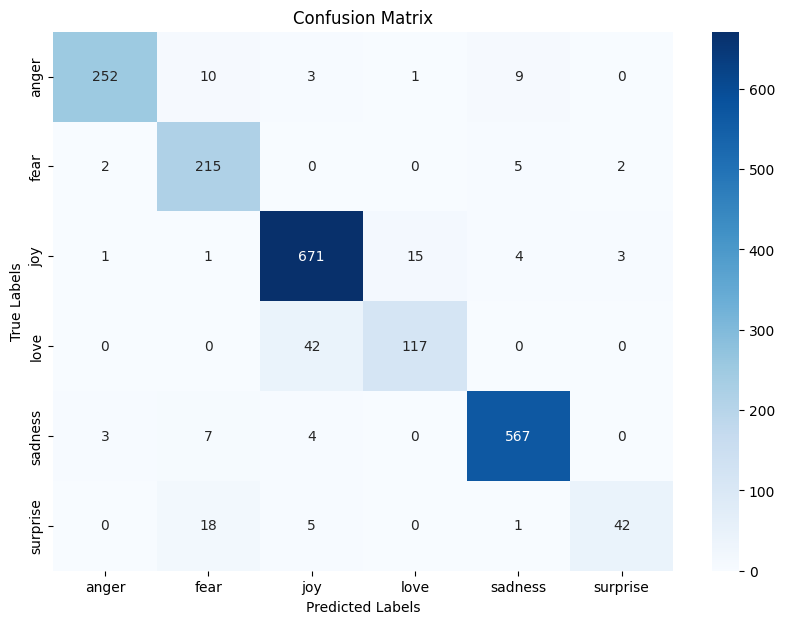

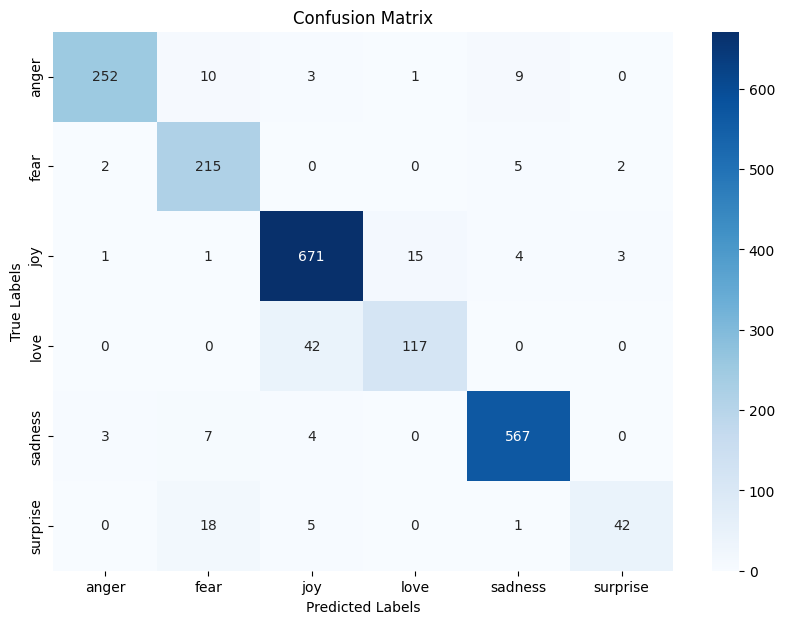

In [19]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns  # For better visualization of confusion matrices
# Assuming y_pred_labels and y_true are defined from previous steps

# Compute the confusion matrix
conf_matrix = confusion_matrix(y_true, y_pred_labels)
# Define labels if necessary; adjust according to your dataset
labels = label_encoder.classes_

# Plotting the confusion matrix
plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()
